In [22]:
import numpy as np
import pandas as pd
# import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import matplotlib, seaborn, openpyxl, sys

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay)

# %pip install scikit-learn    # solo 1 vez
# %pip install openpyxl
print(openpyxl.__version__)


3.1.5


en terminal instalo:

py -m pip install --upgrade pip

py -m pip install --upgrade numpy scipy pandas statsmodels

In [ ]:
%pip uninstall -y statsmodels
%pip install --no-cache-dir statsmodels

print(sys.version)
print(sys.executable)

   id  depresion  estres  apoyo_social  autoestima  horas_sueno  hco_familiar  \
0   1          0     1.8           4.7         2.0          9.4             0   
1   2          1     8.7           2.4         4.0          6.0             0   
2   3          1     8.9           4.4         1.1          8.4             0   
3   4          0     8.1           1.2         9.2          7.4             0   
4   5          0     5.7           5.3         8.4          7.8             0   

   cafeina  sexo  edad  
0      3.2     0    35  
1      0.0     1    39  
2      0.3     1    23  
3      5.0     0    26  
4      5.8     1    39  
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            200 non-null    int64  
 1   depresion     200 non-null    int64  
 2   estres        200 non-null    float64
 3   apoyo_social  200 non-null    float64
 4   autoes

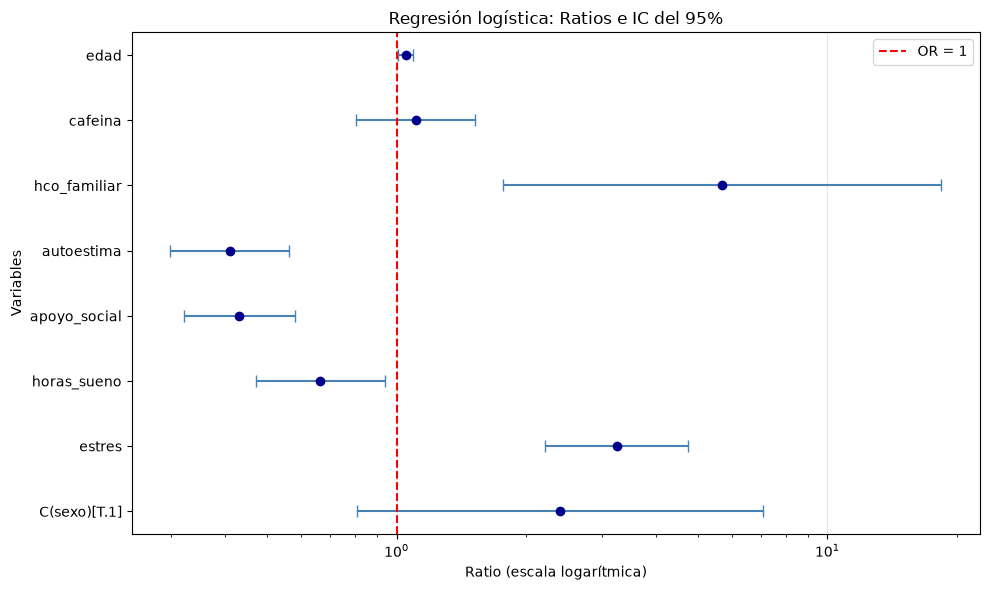


Rdos exportados Ok.


In [27]:

# -----------------------------------
# 1. IMPORTAR DATOS DE EXCEL
# -----------------------------------

df = pd.read_excel('Src/Data/BD_depresion.xlsx', engine='openpyxl')

# Comprobar los datos
print(df.head())
print(df.info())
print(df.columns.tolist())

# -----------------------------------
# 2. PREPARAR VBLES
# -----------------------------------

# Eliminar registros con datos ausentes en las variables usadas
variables = ['depresion', 'estres', 'horas_sueno','apoyo_social', 'autoestima', 'hco_familiar', 'cafeina', 'sexo', 'edad']
df = df.dropna(subset=variables).copy()

# -----------------------------------
# 3. REGRESIÓN LOGÍSTICA BINARIA
# -----------------------------------

formula = ('depresion ~ estres + horas_sueno + apoyo_social + autoestima + hco_familiar + cafeina + C(sexo) + edad')
modelo = smf.logit(formula=formula, data=df).fit( method='bfgs', maxiter=500, disp=False)

# -----------------------------------
# 4. RESUMEN ESTADÍSTICO
# -----------------------------------

print("\n--- RESUMEN DEL MODELO ---")
print(modelo.summary())

# -----------------------------------
# 5. RATIOS E IC DEL 95%
# -----------------------------------

params = modelo.params
conf = modelo.conf_int()

rdos = pd.DataFrame({
    'Ratio': np.exp(params),
    'IC_95%_inferior': np.exp(conf[0]),
    'IC_95%_superior': np.exp(conf[1]),
    'p_valor': modelo.pvalues
})

print("\n--- RATIOS E INTERVALOS DE CONFIANZA ---")
print(rdos.round(3))

# -----------------------------------
# 6. GRÁFICO DE RATIOS
# -----------------------------------

# Excluir el intercepto del gráfico
grafico = rdos.drop(index='Intercept', errors='ignore')

plt.figure(figsize=(10, 6))

plt.errorbar(grafico['Ratio'], range(len(grafico)), xerr=[ grafico['Ratio'] - grafico['IC_95%_inferior'],
                                                           grafico['IC_95%_superior'] - grafico['Ratio']],
                                                     fmt='o', color='darkblue', ecolor='steelblue', capsize=4)

plt.axvline( x=1,  color='red',  linestyle='--', label='OR = 1')

plt.yticks(range(len(grafico)), grafico.index)
plt.xscale('log')
plt.xlabel('Ratio (escala logarítmica)')
plt.ylabel('Variables')
plt.title('Regresión logística: Ratios e IC del 95%')
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------------
# 7. EXPORTAR RDOS A EXCEL
# -----------------------------------

rdos.to_excel('Rdos_regresion_logistica.xlsx')
print("\nRdos exportados Ok.")


Interpretación estadística

OR > 1: asociación con mayores de presentar depresión.

OR < 1: asociación con menores de presentar depresión.

OR = 1: ausencia de asociación en términos de ratio.

p menor de 0,05: evidencia estadística de asociación.

IC 95 % que no incluye 1: evidencia estadística de asociación al nivel aproximado del 5 %.

4. Una cuestión importante
Para que el análisis funcione correctamente, necesito confirmar algo:

¿Tu archivo Excel tiene exactamente estos nombres de columnas?

depresion, estress, horas_sueno, apoyo_social, autoestima, hco_familiar, cafeina, sexo, edad.

Si me adjuntas el archivo BD_depresion.xlsx, puedo ayudarte a adaptar el código a sus columnas reales y preparar la tabla de resultados para tu investigación.

Num participantes: 200

 Col BBDD: ['id', 'depresion', 'estres', 'apoyo_social', 'autoestima', 'horas_sueno', 'hco_familiar', 'cafeina', 'sexo', 'edad'] 


    id  depresion  estres  apoyo_social  autoestima  horas_sueno  hco_familiar  \
0   1          0     1.8           4.7         2.0          9.4             0   
1   2          1     8.7           2.4         4.0          6.0             0   
2   3          1     8.9           4.4         1.1          8.4             0   
3   4          0     8.1           1.2         9.2          7.4             0   
4   5          0     5.7           5.3         8.4          7.8             0   

   cafeina  sexo  edad  
0      3.2     0    35  
1      0.0     1    39  
2      0.3     1    23  
3      5.0     0    26  
4      5.8     1    39  
REGRESIÓN LOGÍSTICA 
 -------------------------

Exactitud: 1.0
\ RATIOS
       Variable  Coeficiente    Ratio
0     depresion        6.807  903.905
1        estres        0.303    1.355
2   horas_sueno    

<>:60: SyntaxWarning: invalid escape sequence '\ '
<>:60: SyntaxWarning: invalid escape sequence '\ '
C:\Users\gemma\AppData\Local\Temp\ipykernel_26568\205195460.py:60: SyntaxWarning: invalid escape sequence '\ '
  print("\ RATIOS")


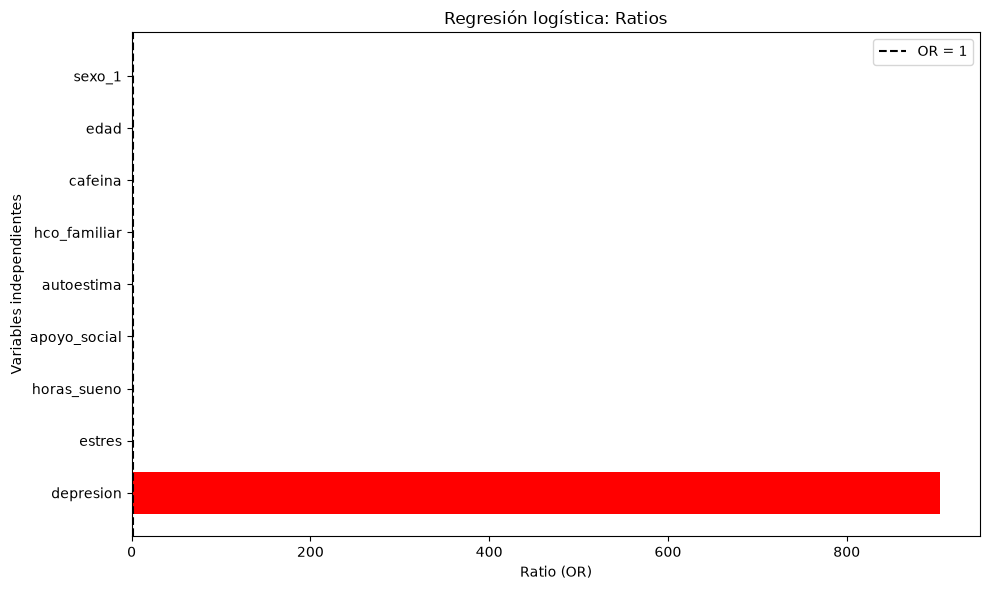

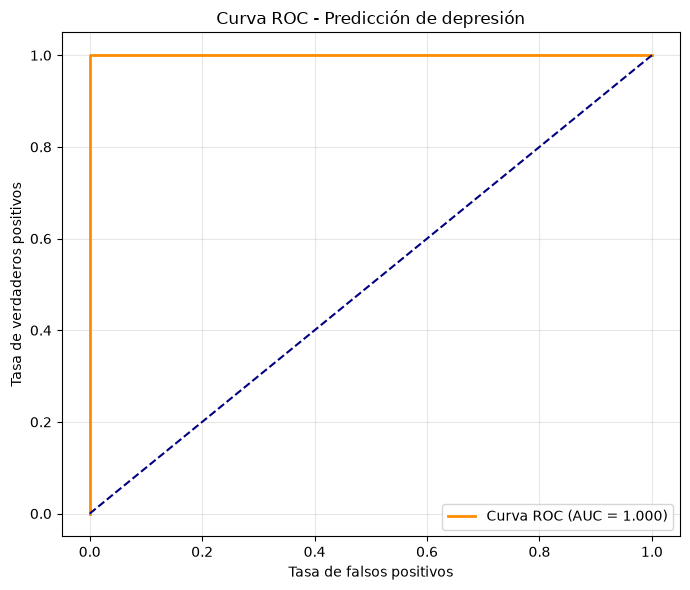

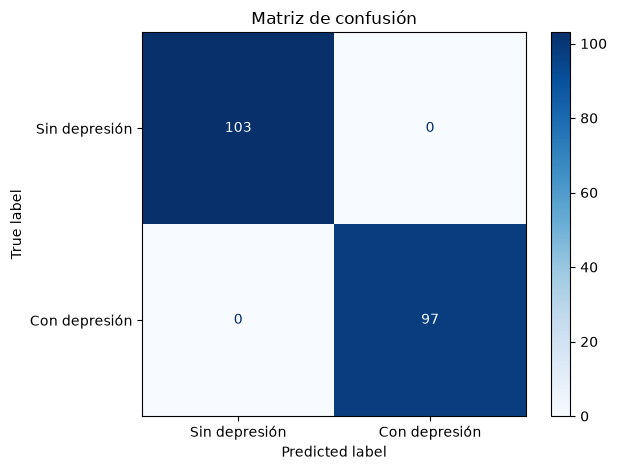

In [18]:
# ----------------------------------
# 1. GENERAR BBDD
# ----------------------------------

df = pd.read_excel('BD_depresion.xlsx', engine='openpyxl')
print("Num participantes:", len(df))

# Mostrar nombres cols
print("\n Col BBDD:", df.columns.tolist(), "\n")

# Mostrar los primeros registros/filas
print("\n", df.head())

formula = ('depresion ~ estres + horas_sueno + apoyo_social + autoestima + hco_familiar + cafeina + C(sexo) + edad')

# ----------------------------------
# 2. PREPARAR VBLES
# ----------------------------------

X = df[['depresion','estres', 'horas_sueno', 'apoyo_social','autoestima', 'hco_familiar', 'cafeina','sexo', 'edad']].copy()

# Convertir sexo en variable nº
X = pd.get_dummies(X, columns=['sexo'], drop_first=True, dtype=int)
y = df['depresion']

# ----------------------------------
# 3. REGRESIÓN LOGÍSTICA
# ----------------------------------

modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modelo.fit(X, y)

# Predicciones
predicciones = modelo.predict(X)
probabilidades = modelo.predict_proba(X)[:, 1]

print("REGRESIÓN LOGÍSTICA \n -------------------------\n")
print("Exactitud:", round(modelo.score(X, y), 3))

# ----------------------------------
# 4. RATIOS
# ----------------------------------

regresion = modelo.named_steps['logisticregression']
scaler = modelo.named_steps['standardscaler']

# Recuperar coeficientes en escala original
coeficientes = regresion.coef_[0] / scaler.scale_

# Ajustar intercepto
intercepto = (regresion.intercept_[0] - np.sum(regresion.coef_[0] * scaler.mean_ / scaler.scale_))
ratios = np.exp(coeficientes)

rdos = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': coeficientes,
    'Ratio': ratios
})

print("\ RATIOS")
print(rdos.round(3))

# ----------------------------------
# 5. GRÁFICO DE RATIOS
# ----------------------------------

plt.figure(figsize=(10, 6))
colores = ['red' if valor > 1 else 'steelblue'  for valor in ratios]

plt.barh( rdos['Variable'], rdos['Ratio'], color=colores)
plt.axvline( x=1, color='black', linestyle='--', label='OR = 1')

plt.xlabel('Ratio (OR)')
plt.ylabel('Variables independientes')
plt.title('Regresión logística: Ratios')
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------
# 6. CURVA ROC
# ----------------------------------

fpr, tpr, thresholds = roc_curve(y, probabilidades)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot( fpr, tpr, color='darkorange', linewidth=2, label=f'Curva ROC (AUC = {roc_auc:.3f})')
plt.plot( [0, 1], [0, 1], color='navy', linestyle='--')

plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC - Predicción de depresión')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------------
# 7. MATRIZ DE CONFUSIÓN
# ----------------------------------

cm = confusion_matrix(y, predicciones)

disp = ConfusionMatrixDisplay( confusion_matrix=cm, display_labels=['Sin depresión', 'Con depresión'])
disp.plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión')
plt.tight_layout()
plt.show()


Gráfico 1. Ratios:  Visualiza q vbles presentan una asociación positiva o negativa con la depresión.

Gráfico 2. Curva ROC: Evalúa la capacidad discriminativa del modelo mediante el AUC.

Gráfico 3. Matriz de confusión: Muestra los casos clasificados correctamente e incorrectamente.

Consideraciones, 3 cuestiones:

Los OR calculados corresponden a incrementos de una unidad de cada variable original.
Este código no calcula intervalos de confianza ni valores p. Para contrastar las hipótesis necesitarás un método inferencial adicional.
La exactitud y la curva ROC se calculan sobre los mismos datos usados para entrenar el modelo, por lo que son resultados descriptivos optimistas. Para evaluar la capacidad predictiva sería preferible usar una muestra de prueba.

Para contrastar la Hipótesis 1 y la Hipótesis 2 mediante regresión logística binaria, conviene obtener tb una tabla final con OR, IC del 95 % y valores p. Así tengo rdos más adecuados.